# 03 · How long until a case ends? Still-open curves and groups of districts

Kaplan–Meier "share still open after N months" for Tamil Nadu filings 2015–2018, then k-means
on district profiles (a syllabus algorithm), with k chosen by silhouette.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import matplotlib.pyplot as plt
import pandas as pd

from tareekh import plotstyle as ps

ps.apply()
CLEAN, KEYS, FIG = ROOT / "data/clean", ROOT / "data/raw/ddl/keys", ROOT / "reports/figures"
A = json.loads((ROOT / "reports/analysis.json").read_text())
pd.set_option("display.max_colwidth", 70)

## 1. Share of cases still open after N months

Pending cases count as open until the scrape; transferred cases until their transfer. Dropping them would make courts look far faster.

,cases,median days,open at 12 m,open at 24 m,open at 48 m
all cases,2226923.0,532.0,0.5665,0.4316,0.2464
Summary trial case (petty offences),582598.0,2.0,0.2173,0.1733,0.1050
Original suit (civil),370222.0,834.0,0.7199,0.5361,0.3192
"Calendar case (criminal, magistrate)",369512.0,1326.0,0.7797,0.6656,0.4621
Motor accident claim,280810.0,1243.0,0.8939,0.7404,0.3849
Criminal miscellaneous petition (bail etc.),141795.0,5.0,0.0277,0.0118,0.0037
Execution petition,141997.0,611.0,0.7041,0.4264,0.1639
Hindu marriage petition,62525.0,379.0,0.5138,0.2625,0.0672
Original petition,43866.0,330.0,0.4674,0.2553,0.0652


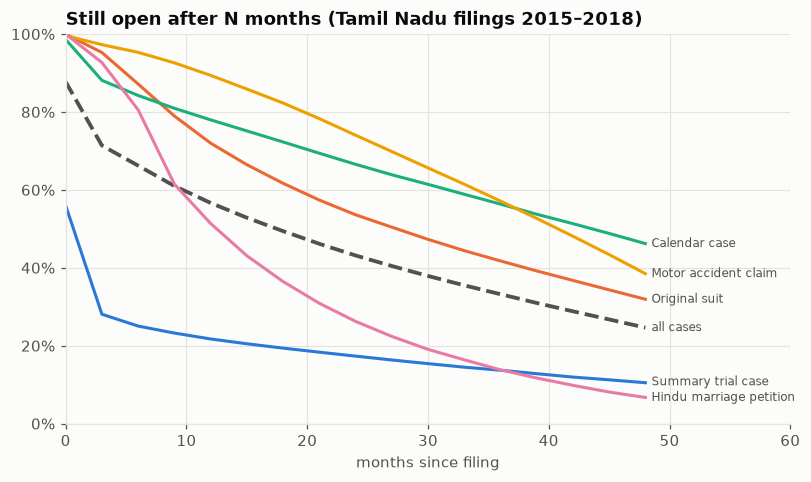

In [2]:
curves = A["tamil_nadu"]["still_open_curves"]
show = ["all cases", "stc", "os", "cc", "mcop", "hmop"]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ends = []
for i, name in enumerate(show):
    cv = curves[name]; months = [int(k) for k in cv["still_open"]]; vals = list(cv["still_open"].values())
    color = ps.INK_2 if name == "all cases" else ps.SERIES[i - 1]
    ax.plot(months, vals, color=color, lw=2.5 if name == "all cases" else 2,
            ls="--" if name == "all cases" else "-")
    ends.append([vals[-1], cv["label"].split(" (")[0], months[-1]])
ends.sort()  # end labels, pushed apart so none overlap (at least 4 points of the y axis)
for j in range(1, len(ends)):
    ends[j][0] = max(ends[j][0], ends[j - 1][0] + 0.04)
for y, text, x in ends:
    ax.annotate(text, (x, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=ps.INK_2)
ax.set_xlim(0, 60); ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("months since filing"); ax.set_title("Still open after N months (Tamil Nadu filings 2015–2018)")
ps.save(fig, "survival_still_open", FIG)
pd.DataFrame({cv["label"]: {"cases": cv["cases"], "median days": cv["median_days"],
                            **{f"open at {m} m": cv["still_open"][str(m)] if str(m) in cv["still_open"] else cv["still_open"][m]
                               for m in (12, 24, 48)}} for cv in curves.values()}).T

## 2. Groups of districts (k-means)

Each district's profile: the share disposed of within a year for six big case types, plus the share of 2015 filings still open at the scrape. Standardised, then k-means for k = 2…8.

chosen k = 3; best silhouette 0.19. Below ~0.25 the structure is weak: districts differ by degree more than by type.
filled with the median: {'Chennai': ['within_1y_hmop'], 'Dindigul': ['within_1y_hmop'], 'Nagapattinam': ['within_1y_hmop']}


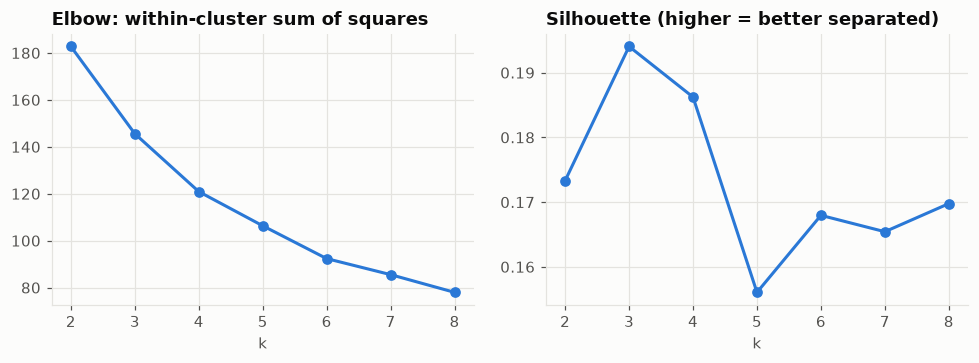

In [3]:
k = A["tamil_nadu"]["district_clusters"]
ks = sorted(int(x) for x in k["silhouette"])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(ks, [k["inertia"][str(x)] for x in ks], marker="o", color=ps.SERIES[0]); axes[0].set_title("Elbow: within-cluster sum of squares")
axes[1].plot(ks, [k["silhouette"][str(x)] for x in ks], marker="o", color=ps.SERIES[0]); axes[1].set_title("Silhouette (higher = better separated)")
for ax in axes: ax.set_xlabel("k")
fig.tight_layout(); ps.save(fig, "clusters_choose_k", FIG)
print(f"chosen k = {k['k']}; best silhouette {max(k['silhouette'].values()):.2f}. "
      "Below ~0.25 the structure is weak: districts differ by degree more than by type.")
print("filled with the median:", k["imputed"])

In [4]:
centres = pd.DataFrame(k["centres"]).T
centres.index = [f"group {i}" for i in centres.index]
members = pd.Series(k["district_cluster"]).groupby(lambda d: k["district_cluster"][d]).apply(lambda s: ", ".join(sorted(s.index)))
centres["districts"] = members.values
centres.style.format({c: "{:.0%}" for c in centres.columns if c != "districts"})

,within_1y_cc,within_1y_ep,within_1y_hmop,within_1y_mcop,within_1y_os,within_1y_stc,open_at_cutoff_2015_filings,districts
group 0,30%,30%,44%,14%,26%,88%,37%,"Chennai, Nagapattinam, Ramanathapuram, Salem, Theni, Tiruchirappalli, Tiruvarur, Vellore, Virudhunagar"
group 1,15%,35%,57%,20%,35%,60%,44%,"Cuddalore, Erode, Kanniyakumari, Karur, Puducherry, Sivagangai, Thanjavur, The Nilgiris, Tirunelveli"
group 2,17%,24%,50%,9%,22%,76%,49%,"Ariyalur, Coimbatore, Dharmapuri, Dindigul, Kancheepuram, Krishnagiri, Madurai, Namakkal, Perambalur, Pudukkottai, Thoothukudi, Tiruppur, Tiruvallur, Tiruvannamalai, Viluppuram"


## Takeaways

- Half of all Tamil Nadu cases filed 2015–2018 are still open after about a year and a half;
  a quarter after four years.
- Case types differ by years, not months: petty summary trials and bail-type petitions end
  within days, while calendar (criminal) cases and accident claims run for years.
- The k-means groups are a *summary*, not a discovery: silhouette is low, so districts form a
  continuum. We report that rather than naming clusters that aren't really there.